# How Do People Shop?

In this notebook we explore a survey about **how people shop in 2026**: where they shop, which device they use, how much ads and reviews influence them, and how often they buy on impulse.

### The 4 question we answer
1. **What does the data look like, and what is wrong with it?** (cleaning)
2. **Who are the shoppers and what do they prefer?** (charts)
3. **Can we group shoppers into types?** (clustering)
4. **Can we predict who is an impulse buyer?** (machine learning)

> **Important:** the 500 rows were *generated from only 7 real answers*. So treat this as a **practice project**. The patterns are good for learning the steps, buy they may not describe real people.

## Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore")

In [2]:
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, silhouette_score
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [3]:
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

## Load and look at the data

In [4]:
df = pd.read_csv("consumer_shopping_behavior_survey.csv")

In [5]:
df.head()

,Response_ID,Timestamp,Age,Gender,Occupation_Status,Country_Region,Monthly_Income_Range,Shop_Most_Where,Online_Shopping_Frequency,Preferred_Platform,...,Return_Frequency,Avg_Monthly_Spend_NonEssentials,Preferred_Payment_Method,Uses_BNPL_Installments,Online_Shopping_Satisfaction_Score,Trust_In_Online_Reviews_Score,Regret_After_Purchase_Frequency,Reason_Prefer_Online,Reason_Prefer_InStore,Best_Shopping_Mode
0,1,01/08/2026 12:30:25,20,Male,NaN,Philippines,"Under $1,000",Equal mix,Often,Physical stores,...,Never,Under $50,Digital wallet,"Yes, occasionally",6.0,7.0,2.0,More variety,No delivery wait,Online
1,2,21/06/2026 13:52:02,24,Male,Employed part-time,Brazil,"Under $1,000",In-store only,Often,Local e-commerce,...,Often,Under $50,Digital wallet,"No, never",5.0,8.0,3.0,NaN,Try product before buying,Offline
2,3,15/08/2026 04:24:18,22,Female,Student,India,"Under $1,000",Equal mix,Always,Local e-commerce,...,Sometimes,$150-300,Credit Card,"No, never",7.0,6.0,2.0,Better prices,Trust,Online
3,4,23/06/2026 21:24:21,20,Male,Student,NaN,"Under $1,000",In-store only,Occasionally,Brand websites,...,Never,Under $50,Debit Card,"No, never",8.0,7.0,3.0,Better prices,Try product before buying,Equal / both
4,5,20/08/2026 16:24:47,41,Male,Employed full-time,United States,"$1,000-3,000",Equal mix,Occasionally,NaN,...,Sometimes,$50-150,Debit Card,"No, never",6.0,8.0,2.0,Convenience,Trust,Equal / both


In [6]:
df.columns

Index(['Response_ID', 'Timestamp', 'Age', 'Gender', 'Occupation_Status',
       'Country_Region', 'Monthly_Income_Range', 'Shop_Most_Where',
       'Online_Shopping_Frequency', 'Preferred_Platform', 'Primary_Device',
       'Top_Spending_Category', 'Review_Influence_Score',
       'Social_Ads_Influence_Score', 'Price_Comparison_Frequency',
       'Discount_Importance_Score', 'Follows_Brands_On_Social',
       'Likely_To_Buy_After_Ad_Score', 'Makes_Shopping_List',
       'Impulse_Purchase_Frequency', 'Return_Frequency',
       'Avg_Monthly_Spend_NonEssentials', 'Preferred_Payment_Method',
       'Uses_BNPL_Installments', 'Online_Shopping_Satisfaction_Score',
       'Trust_In_Online_Reviews_Score', 'Regret_After_Purchase_Frequency',
       'Reason_Prefer_Online', 'Reason_Prefer_InStore', 'Best_Shopping_Mode'],
      dtype='str')

In [7]:
df.shape

(500, 30)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 30 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Response_ID                         500 non-null    int64  
 1   Timestamp                           500 non-null    str    
 2   Age                                 478 non-null    str    
 3   Gender                              484 non-null    str    
 4   Occupation_Status                   479 non-null    str    
 5   Country_Region                      480 non-null    str    
 6   Monthly_Income_Range                479 non-null    str    
 7   Shop_Most_Where                     484 non-null    str    
 8   Online_Shopping_Frequency           481 non-null    str    
 9   Preferred_Platform                  486 non-null    str    
 10  Primary_Device                      492 non-null    str    
 11  Top_Spending_Category               476 non-null    str 

In [9]:
df.isna().sum().sort_values(ascending=False)

Reason_Prefer_Online                  54
Regret_After_Purchase_Frequency       52
Best_Shopping_Mode                    51
Trust_In_Online_Reviews_Score         50
Reason_Prefer_InStore                 45
Online_Shopping_Satisfaction_Score    43
Price_Comparison_Frequency            26
Likely_To_Buy_After_Ad_Score          25
Top_Spending_Category                 24
Makes_Shopping_List                   24
Discount_Importance_Score             23
Age                                   22
Monthly_Income_Range                  21
Social_Ads_Influence_Score            21
Occupation_Status                     21
Country_Region                        20
Avg_Monthly_Spend_NonEssentials       20
Online_Shopping_Frequency             19
Return_Frequency                      17
Impulse_Purchase_Frequency            16
Shop_Most_Where                       16
Gender                                16
Review_Influence_Score                15
Preferred_Payment_Method              15
Preferred_Platfo

**What to notice:** the last six question (Satisfaction, trust, regret, reasons, best mode) have the most missing values(about 43-54 each). Some people stopped the survey before the end.

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
age_as_number = pd.to_numeric(df["Age"], errors="coerce")
bad_ages = df.loc[age_as_number.isna() & df["Age"].notna(), 'Age']
print("Not-a-number ages:", bad_ages.tolist())

Not-a-number ages: ['rahul', 'test', 'xyz', 'N/A123', 'asdf', '...', 'Gunay B', 'Priya K']


There are junk entries like `test` and `xyz`. We will turn them into "missing" instead of gussing an age.

In [12]:
df["Age"] = pd.to_numeric(df["Age"], errors= 'coerce')
df["Timestamp"] = pd.to_datetime(df["Timestamp"], format= "%d/%m/%Y %H:%M:%S")

In [13]:
df[["Age","Timestamp"]].dtypes

Age                 float64
Timestamp    datetime64[us]
dtype: object

In [14]:
df["Age"].describe()

count    470.000000
mean      25.019149
std        7.515276
min       16.000000
25%       20.000000
50%       22.000000
75%       30.000000
max       50.000000
Name: Age, dtype: float64

In [15]:
df["Reason_Prefer_Online"].value_counts()

Reason_Prefer_Online
More variety      170
Convenience       157
Better prices      81
Not applicable     38
Name: count, dtype: int64

In [16]:
df["Top_Spending_Category"] = df["Top_Spending_Category"].str.capitalize()
df["Top_Spending_Category"].value_counts()

Top_Spending_Category
Clothing                  179
Groceries                  92
Electronics                76
Miscellaneous              55
Books                      38
Beauty & personal care     36
Name: count, dtype: int64

In [17]:
bins = [0, 18, 25, 35, 50, 100]

labels = ["under 18", "18-25", "26-35", "36-50", "50+"]
df["Age_Group"] = pd.cut(df["Age"], bins = bins, labels= labels)

In [18]:
df["Age_Group"].value_counts()

Age_Group
18-25       228
26-35       110
under 18     78
36-50        54
50+           0
Name: count, dtype: int64

In [19]:
cols_to_fill = ["Gender", "Occupation_Status", "Country_Region", "Monthly_Income_Range", "Shop_Most_Where",
                "Online_Shopping_Frequency", "Preferred_Platform", "Primary_Device", "Top_Spending_Category",
                "Follows_Brands_On_Social", "Makes_Shopping_List", "Return_Frequency",
                "Avg_Monthly_Spend_NonEssentials", "Preferred_Payment_Method", "Uses_BNPL_Installments",
                "Reason_Prefer_Online", "Reason_Prefer_InStore", "Best_Shopping_Mode"]

In [20]:
for col in cols_to_fill:
    df[col] = df[col].fillna("Unknown")

In [21]:
df[cols_to_fill].isna().sum()

Gender                             0
Occupation_Status                  0
Country_Region                     0
Monthly_Income_Range               0
Shop_Most_Where                    0
Online_Shopping_Frequency          0
Preferred_Platform                 0
Primary_Device                     0
Top_Spending_Category              0
Follows_Brands_On_Social           0
Makes_Shopping_List                0
Return_Frequency                   0
Avg_Monthly_Spend_NonEssentials    0
Preferred_Payment_Method           0
Uses_BNPL_Installments             0
Reason_Prefer_Online               0
Reason_Prefer_InStore              0
Best_Shopping_Mode                 0
dtype: int64

In [22]:
df.columns

Index(['Response_ID', 'Timestamp', 'Age', 'Gender', 'Occupation_Status',
       'Country_Region', 'Monthly_Income_Range', 'Shop_Most_Where',
       'Online_Shopping_Frequency', 'Preferred_Platform', 'Primary_Device',
       'Top_Spending_Category', 'Review_Influence_Score',
       'Social_Ads_Influence_Score', 'Price_Comparison_Frequency',
       'Discount_Importance_Score', 'Follows_Brands_On_Social',
       'Likely_To_Buy_After_Ad_Score', 'Makes_Shopping_List',
       'Impulse_Purchase_Frequency', 'Return_Frequency',
       'Avg_Monthly_Spend_NonEssentials', 'Preferred_Payment_Method',
       'Uses_BNPL_Installments', 'Online_Shopping_Satisfaction_Score',
       'Trust_In_Online_Reviews_Score', 'Regret_After_Purchase_Frequency',
       'Reason_Prefer_Online', 'Reason_Prefer_InStore', 'Best_Shopping_Mode',
       'Age_Group'],
      dtype='str')

In [23]:
last6 = ['Online_Shopping_Satisfaction_Score',
       'Trust_In_Online_Reviews_Score', 'Regret_After_Purchase_Frequency',
       'Reason_Prefer_Online', 'Reason_Prefer_InStore', 'Best_Shopping_Mode']

In [24]:
dropoff = df[last6].isna().all(axis=1)

In [25]:
dropoff.sum()

np.int64(0)

In [26]:
df.loc[dropoff, "Timestamp"].dt.date.value_counts().sort_index()

Series([], Name: count, dtype: int64)

In [27]:
pd.crosstab(df["Shop_Most_Where"], df["Reason_Prefer_InStore"], dropna = False)

Reason_Prefer_InStore,No delivery wait,Not applicable,Trust,Try product before buying,Unknown
Shop_Most_Where,,,,,
Equal mix,54,42,49,74,29
In-store only,15,10,16,21,9
Online only,43,20,51,46,5
Unknown,7,0,3,4,2


In [28]:
age_summary = df.groupby("Age_Group", observed= True).agg(
    avg_satisfaction = ("Online_Shopping_Satisfaction_Score", "mean"),
    avg_trust = ("Trust_In_Online_Reviews_Score", "mean"),
    avg_regret = ("Regret_After_Purchase_Frequency", "mean"),
    respondents = ("Response_ID", "count")
).round(2)

In [29]:
age_summary

,avg_satisfaction,avg_trust,avg_regret,respondents
Age_Group,,,,
under 18,7.25,6.06,2.06,78
18-25,7.04,6.11,2.29,228
26-35,7.17,6.14,2.17,110
36-50,7.02,6.48,1.93,54


In [30]:
top_countries = df["Country_Region"].value_counts().head(8).index

In [31]:
top_countries

Index(['India', 'United States', 'Brazil', 'Mexico', 'Indonesia', 'Kenya',
       'Egypt', 'Philippines'],
      dtype='str', name='Country_Region')

In [32]:
country_summary = df[df["Country_Region"].isin(top_countries)].groupby("Country_Region").agg(
    avg_satisfaction = ("Online_Shopping_Satisfaction_Score", "mean"),
    bnpl_regular_rate = ("Uses_BNPL_Installments", lambda X: (X == "Yes, regularly").mean()),
    respondents = ("Response_ID", 'count')
)

country_summary

,avg_satisfaction,bnpl_regular_rate,respondents
Country_Region,,,
Brazil,7.114286,0.184211,38
Egypt,6.521739,0.040000,25
India,6.779661,0.181818,66
Indonesia,7.434783,0.153846,26
Kenya,7.240000,0.269231,26
Mexico,7.250000,0.085714,35
Philippines,7.090909,0.086957,23
United States,7.387755,0.053571,56


In [33]:
occupation_summary = df.groupby("Occupation_Status").agg(
    avg_impulse = ('Impulse_Purchase_Frequency', "mean"),
    avg_discount_importance = ("Discount_Importance_Score", "mean"),
    bnpl_regular_rate = ("Uses_BNPL_Installments", lambda x: (x == "Yes, regularly").mean()),
    respondents = ("Response_ID", "count")
).round(2).sort_values("avg_impulse", ascending=False)
occupation_summary

,avg_impulse,avg_discount_importance,bnpl_regular_rate,respondents
Occupation_Status,,,,
Employed part-time,2.86,3.94,0.10,71
Student,2.61,3.80,0.13,238
Unknown,2.50,3.67,0.05,21
Employed full-time,2.46,3.90,0.14,118
Self-employed,2.45,3.78,0.12,33
Unemployed,2.44,3.47,0.05,19


In [34]:
pivot_payment = pd.pivot_table(
    df, index = "Shop_Most_Where", columns= "Preferred_Payment_Method",
    values = "Response_ID", aggfunc = "count", fill_value=0
)

In [35]:
pivot_payment_pct = pivot_payment.div(pivot_payment.sum(axis = 1), axis = 0).round(2)

In [36]:
pivot_payment_pct

Preferred_Payment_Method,Cash,Credit Card,Debit Card,Digital wallet,Unknown
Shop_Most_Where,,,,,
Equal mix,0.14,0.21,0.27,0.35,0.02
In-store only,0.14,0.25,0.23,0.34,0.04
Online only,0.11,0.22,0.24,0.39,0.03
Unknown,0.12,0.12,0.31,0.38,0.06


In [37]:
pivot_gender_spend = pd.pivot_table(
    df, index = "Gender", columns= "Top_Spending_Category",
    values= "Response_ID", aggfunc= "count", fill_value = 0
)

In [38]:
pivot_gender_spend_pct = pivot_gender_spend.div(pivot_gender_spend.sum(axis=1), axis = 0).round(2)

In [39]:
pivot_gender_spend_pct

Top_Spending_Category,Beauty & personal care,Books,Clothing,Electronics,Groceries,Miscellaneous,Unknown
Gender,,,,,,,
Female,0.06,0.08,0.36,0.13,0.20,0.12,0.04
Male,0.08,0.06,0.38,0.15,0.17,0.10,0.05
Prefer not to say,0.10,0.10,0.22,0.24,0.18,0.14,0.04
Unknown,0.00,0.12,0.38,0.12,0.19,0.12,0.06


**Cleaning done**. We have the same 500 rows, but with proper types, consistent labels, and no confusing blanks in text columns.

## EDA

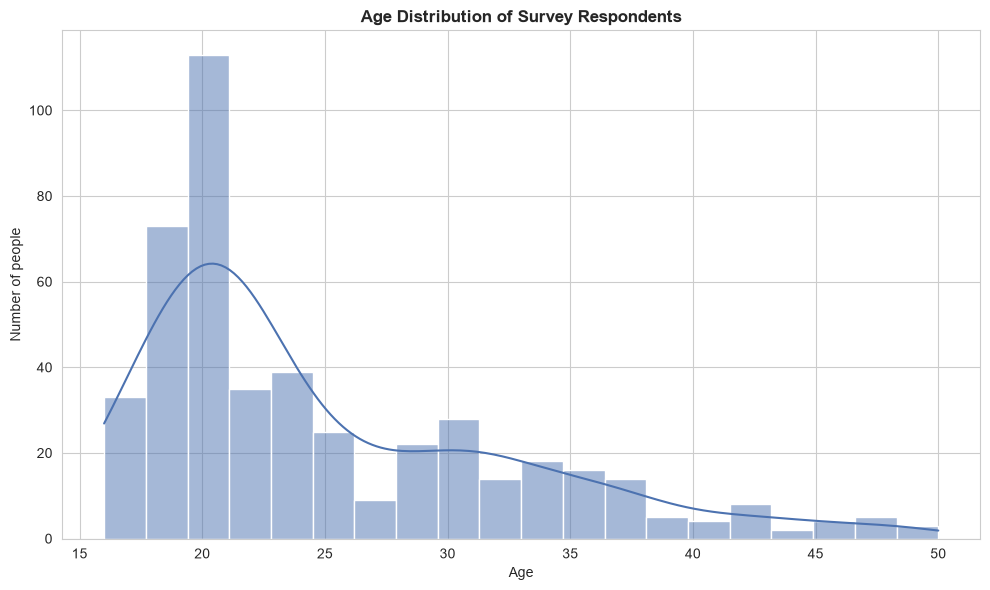

Median age: 22.0


In [40]:
sns.histplot(df["Age"].dropna(), bins = 20, kde= True, color = "#4C72B0")
plt.title("Age Distribution of Survey Respondents", fontweight = 'bold')
plt.xlabel("Age")
plt.ylabel("Number of people")
plt.tight_layout()
plt.show()

print("Median age:", df["Age"].median())

**What we see:** most respondents are young, The median age is 22, and most people are between about 20 and 30. Very few are older than 40.

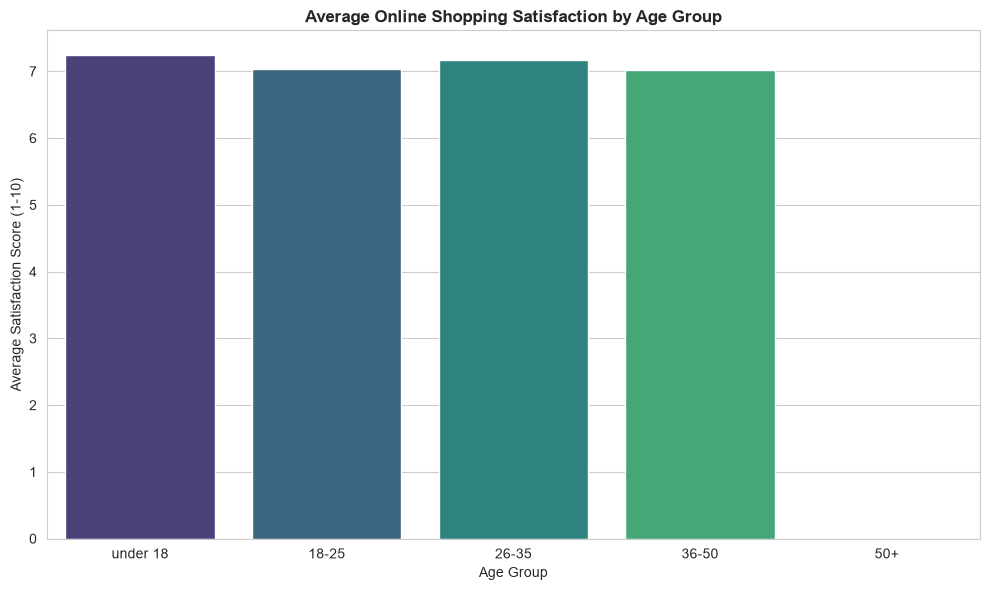

In [41]:
sns.barplot(x = age_summary.index, y = age_summary["avg_satisfaction"],palette="viridis")
plt.title("Average Online Shopping Satisfaction by Age Group", fontweight = "bold")
plt.xlabel("Age Group")
plt.ylabel("Average Satisfaction Score (1-10)")
plt.tight_layout()
plt.show()

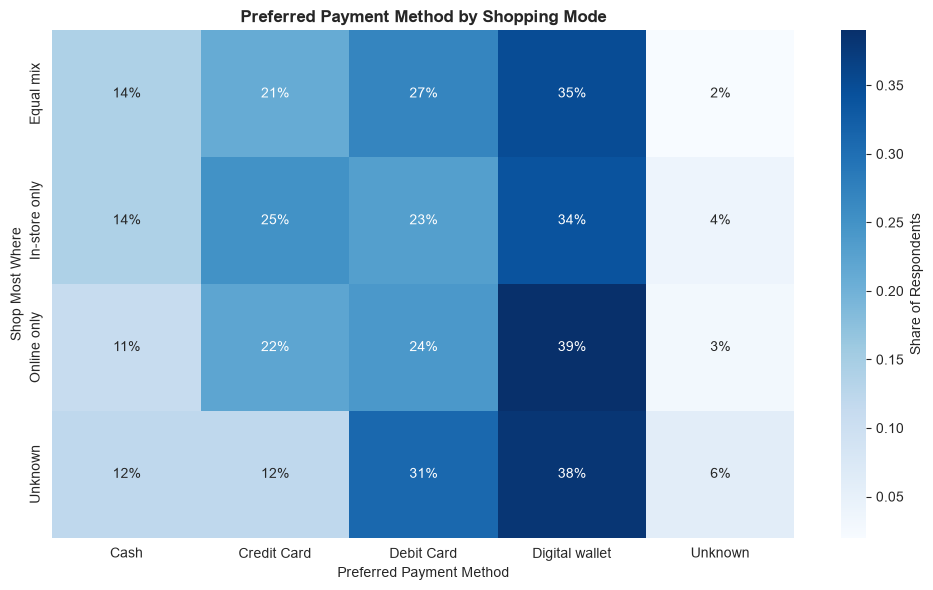

In [42]:
sns.heatmap(pivot_payment_pct, annot= True, cmap= "Blues", fmt= ".0%", cbar_kws= {"label":"Share of Respondents"})
plt.title("Preferred Payment Method by Shopping Mode", fontweight = "bold")
plt.xlabel("Preferred Payment Method")
plt.ylabel("Shop Most Where")
plt.tight_layout()
plt.show()

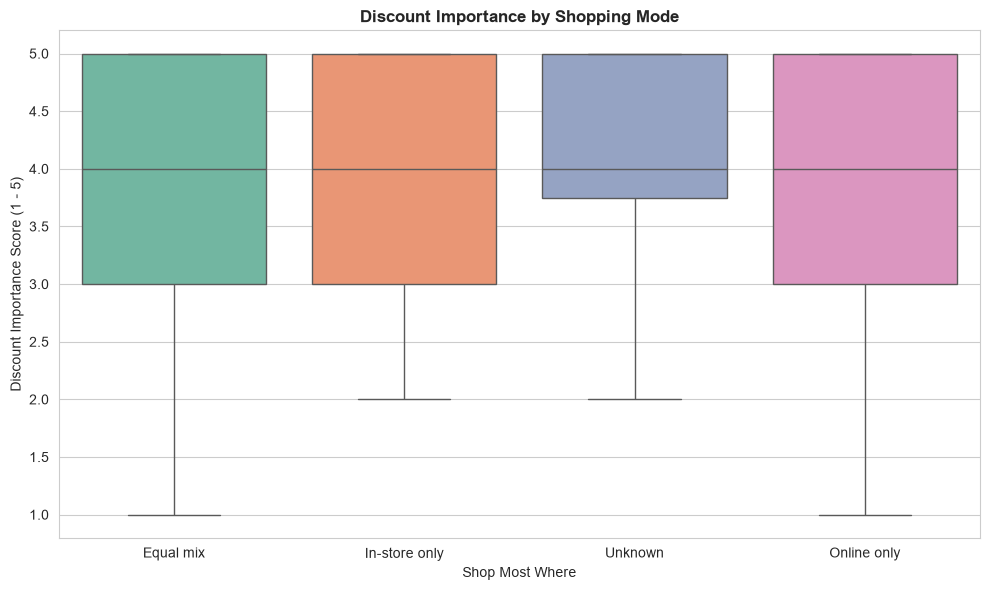

In [43]:
sns.boxplot(x = "Shop_Most_Where", y = "Discount_Importance_Score", data = df, palette= "Set2")
plt.title("Discount Importance by Shopping Mode", fontweight = "bold")
plt.xlabel("Shop Most Where")
plt.ylabel("Discount Importance Score (1 - 5)")
plt.tight_layout()
plt.show()

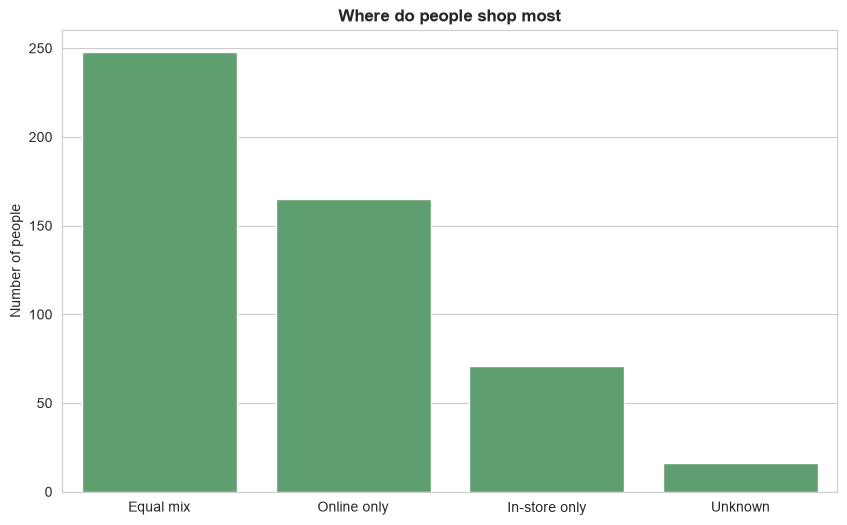

In [44]:
order = df["Shop_Most_Where"].value_counts().index
sns.countplot(data=df, x="Shop_Most_Where", order=order, color='#55A868')
plt.title("Where do people shop most", fontweight='bold')
plt.xlabel("")
plt.ylabel("Number of people")
plt.show()

Half of the people (about 50%) shop in **mix** of online and in-store. About a third shop **Online only**, and only about 14% shop **in-store only**.

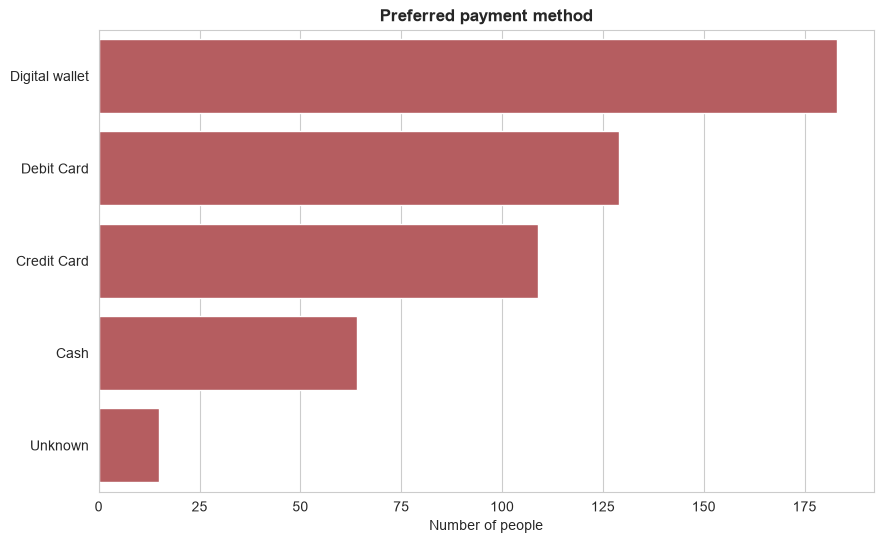

In [45]:
order = df["Preferred_Payment_Method"].value_counts().index
sns.countplot(data = df, y="Preferred_Payment_Method", order= order, color = "#C44E52")
plt.title("Preferred payment method", fontweight = "bold")
plt.xlabel("Number of people")
plt.ylabel("")
plt.show()

**digital wallet** is the ,ost popular way to pay (about 37%), followed by debit card(26%), credit card (22%) and cash (13%).

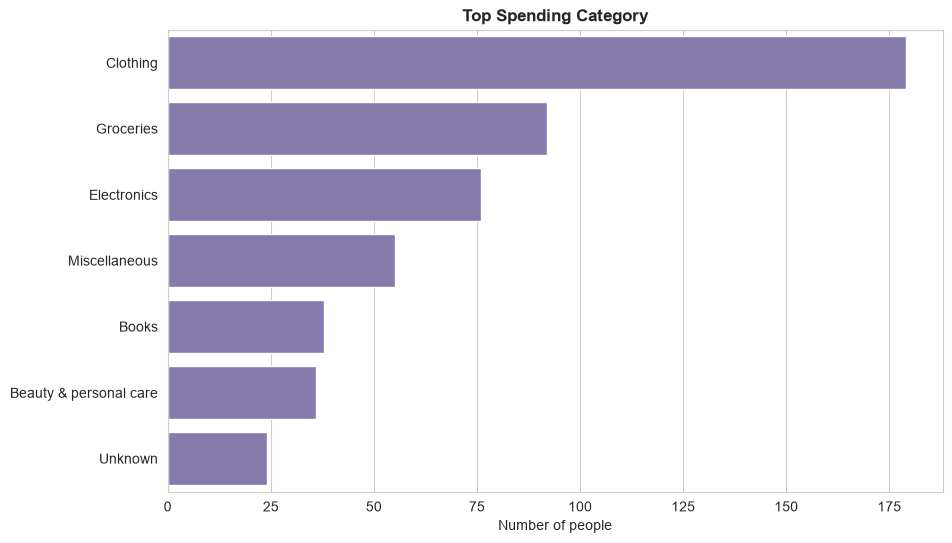

In [46]:
order = df["Top_Spending_Category"].value_counts().index
sns.countplot(data=df, y="Top_Spending_Category", order=order, color = "#8172B2")
plt.title("Top Spending Category", fontweight = 'bold')
plt.xlabel("Number of people")
plt.ylabel("")
plt.show()

**Clothing** is the biggest spending category (about 36% of people), followed by groceries (18%) and electronics(15%).

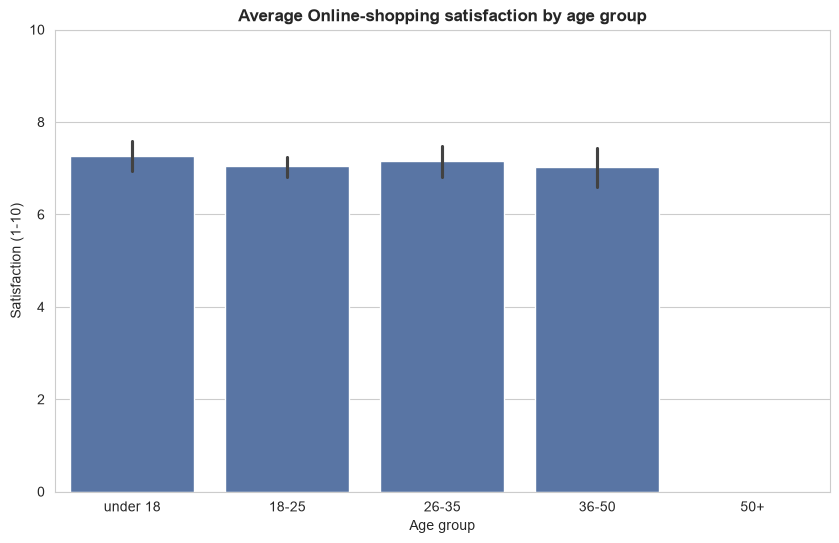

In [47]:
sns.barplot(data=df, x="Age_Group", y="Online_Shopping_Satisfaction_Score", order = labels, color="#4C72B0")
plt.title("Average Online-shopping satisfaction by age group", fontweight = "bold")
plt.xlabel("Age group")
plt.ylabel("Satisfaction (1-10)")
plt.ylim(0,10)
plt.show()

Under-18s look slightly happier (about 7.6), while the other groups are all around 7.0-7.2. But the black lines overlap and the youngest group is small, so these differences are small and may be just luck.

**Conclusion:** no clear age effect on satisfaction.

In [48]:
impulse_by_job = df.groupby("Occupation_Status")["Impulse_Purchase_Frequency"].mean().sort_values()
impulse_by_job.round(2)

Occupation_Status
Unemployed            2.44
Self-employed         2.45
Employed full-time    2.46
Unknown               2.50
Student               2.61
Employed part-time    2.86
Name: Impulse_Purchase_Frequency, dtype: float64

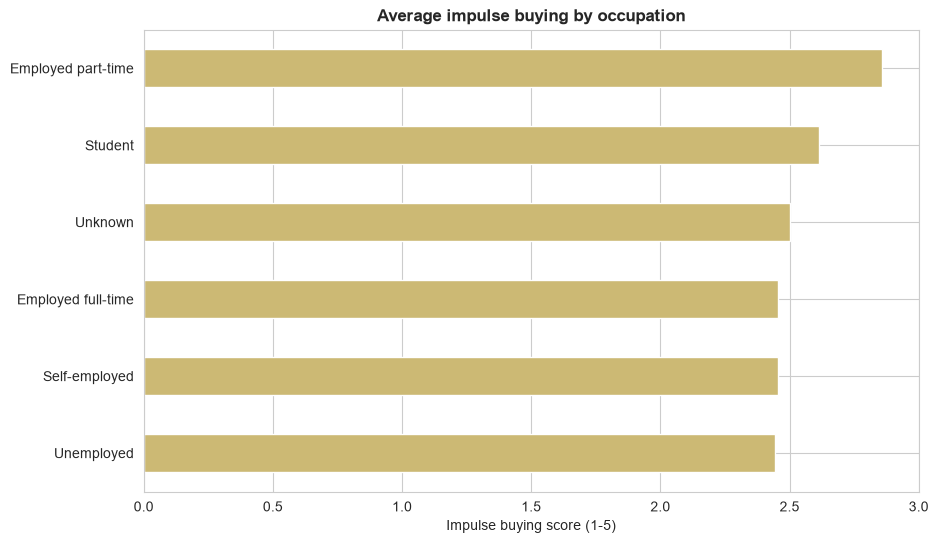

In [49]:
impulse_by_job.plot(kind='barh', color = "#CCB974")
plt.title("Average impulse buying by occupation", fontweight="bold")
plt.xlabel("Impulse buying score (1-5)")
plt.ylabel("")
plt.show()

part-time employees have the highest impluse score (2.86). All other jobs are between 2.44 and 2.61.

**Conclusion:** the gaps are small (less than half a pionts scales), so don't read too much into them. The advanced notebook runs a proper statistical test, and it slso finds that these gaps could be luck.

### Heatmap

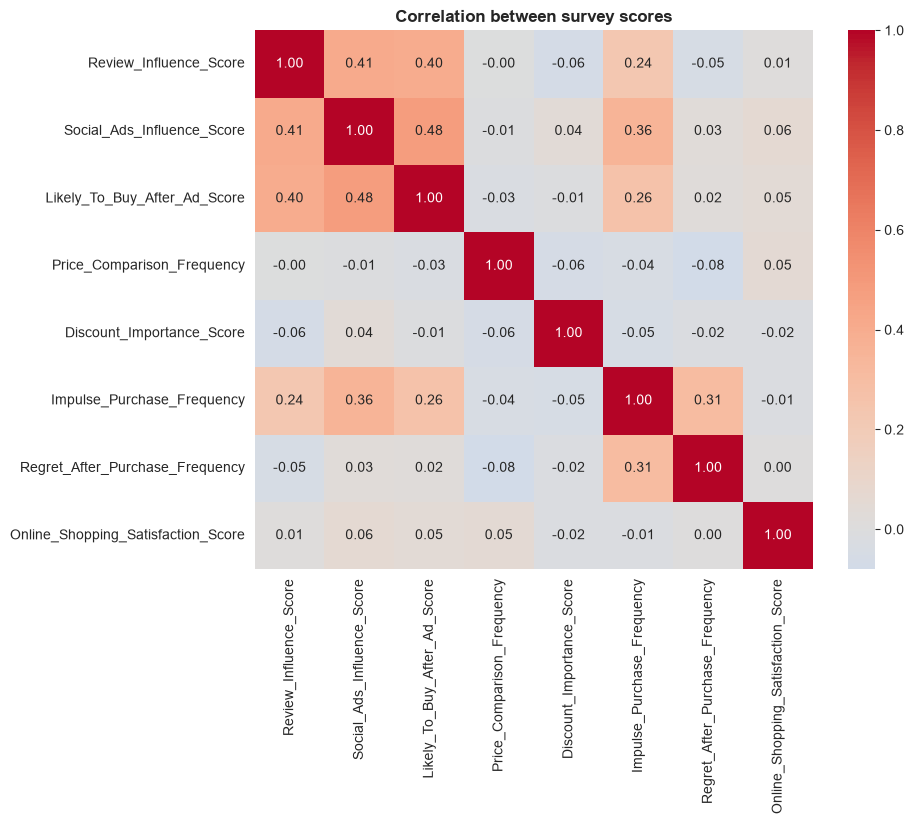

In [50]:
score_columns = ["Review_Influence_Score", "Social_Ads_Influence_Score", "Likely_To_Buy_After_Ad_Score",
                 "Price_Comparison_Frequency", "Discount_Importance_Score", "Impulse_Purchase_Frequency",
                 "Regret_After_Purchase_Frequency", "Online_Shopping_Satisfaction_Score"]

correlations = df[score_columns].corr(method="spearman")

plt.figure(figsize=(9, 7))
sns.heatmap(correlations, annot=True, fmt=".2f", cmap="coolwarm", center = 0)
plt.title("Correlation between survey scores", fontweight = "bold")
plt.show()

- **Ads, reviews and buying after an ad go together** (0.40 to 0.48).People who are influenced by one tend to be influenced by the others.
- **Impulse buying goes with social-ad influence(0.36)** and with regret (0.31). People who react to ads buy more on impulse, and impluse buyers report more regret.
-  **Satisfaction has almost no relationship with anything** (all values near 0).
- Price comparsion and discount importance don't relate to the other scores.

Corrleation is not the same as cause. These scores moving together does not prove that one cause the othre.

### Scaling

In [51]:
decision_columns = ["Review_Influence_Score", "Social_Ads_Influence_Score", "Price_Comparison_Frequency",
                    "Discount_Importance_Score", "Likely_To_Buy_After_Ad_Score", "Impulse_Purchase_Frequency"]

X_groups = df[decision_columns].fillna(df[decision_columns].median())
X_scaled = StandardScaler().fit_transform(X_groups)

### Grouping

In [52]:
for k in range(2, 7):
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_scaled)
    print(f'{k} groups -> silhouette score = {silhouette_score(X_scaled, labels):.2f}')

2 groups -> silhouette score = 0.20
3 groups -> silhouette score = 0.19
4 groups -> silhouette score = 0.17
5 groups -> silhouette score = 0.15
6 groups -> silhouette score = 0.16


all score are low (0.15 to 0.20; a score of 1 would mean perfectly separate groups). So shoppers do **not** fall into sharply separates types, and the groups overlap.

we still use **3 groups**: the score is almost the same as for 2 groups (0.19 vs 0.20), and 3 groups give a more useful description.

In [53]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
df["Group"] = kmeans.fit_predict(X_scaled)

print(df["Group"].value_counts().sort_index())

Group
0     89
1    180
2    231
Name: count, dtype: int64


In [54]:
group_profile = df.groupby("Group")[decision_columns].mean().round(2)
group_profile

,Review_Influence_Score,Social_Ads_Influence_Score,Price_Comparison_Frequency,Discount_Importance_Score,Likely_To_Buy_After_Ad_Score,Impulse_Purchase_Frequency
Group,,,,,,
0,3.06,2.96,2.62,3.91,3.10,2.66
1,3.85,4.06,4.46,3.68,3.86,3.20
2,2.43,2.35,4.51,3.90,2.29,2.08


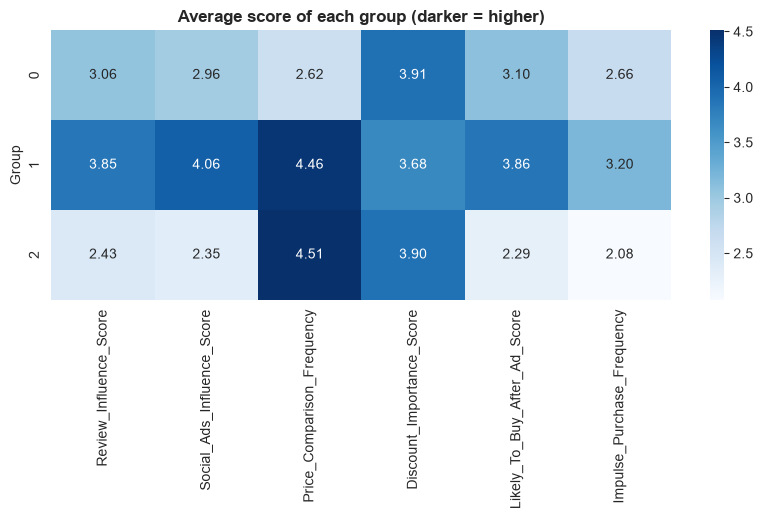

In [55]:
plt.figure(figsize=(10, 3.5))
sns.heatmap(group_profile, annot=True, cmap="Blues", fmt=".2f")
plt.title("Average score of each group (darker = higher)", fontweight = "bold")
plt.show()

**Reading the table** (each number is the group's average score):

- **Group 1 (36% of people)** has the highest scores for reviews (3.85), social ads (4.06), buying after an ad (3.86) and impulse buying (3.20). These are the easily-influenced shopppers.

- **Group 2 (46%)** has the lowest reviews, ads and impulse scores (all around 2.1 to 2.4) but compares prices a lot (4.51). These shoppers decide for themselves.

- **Group 0 (18%)** has medium influence scores but compares prices much less(2.62).

The groups are described by how they decide, and they overlap, as the silhouette score warned.

In [56]:
# the numbers 0, 1, 2 are just labels chosen by the computer, so we give each group a readable name
group_names = {0: "Price-relaxed shoppers", 1: "Influened shoppers", 2: "Independent price_checkers"}
df["Group_Name"] = df["Group"].map(group_names)

df["Group_Name"].value_counts()

Group_Name
Independent price_checkers    231
Influened shoppers            180
Price-relaxed shoppers         89
Name: count, dtype: int64

In [57]:
data = df[df["Impulse_Purchase_Frequency"].notna()].copy()
data["High_Impulse"] = (data["Impulse_Purchase_Frequency"] >= 4).astype(int)

print(data["High_Impulse"].value_counts())
print(f"share of high impluse buyers: {data['High_Impulse'].mean():.0%}")

High_Impulse
0    372
1    112
Name: count, dtype: int64
share of high impluse buyers: 23%


### Split into training and test data

In [58]:
feature_columns = ["Age", "Review_Influence_Score", "Social_Ads_Influence_Score", "Price_Comparison_Frequency",
                   "Discount_Importance_Score", "Likely_To_Buy_After_Ad_Score",
                   "Gender", "Occupation_Status", "Shop_Most_Where", "Primary_Device",
                   "Follows_Brands_On_Social", "Makes_Shopping_List"]

X = pd.get_dummies(data[feature_columns], drop_first=True).astype(float)
y = data["High_Impulse"]

print("Clue columns after conversion:", X.shape[1])


Clue columns after conversion: 26


In [59]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state=42, stratify=y)

medians = X_train.median()
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

print("Training people:", len(X_train), "| Test people:", len(X_test))

Training people: 363 | Test people: 121


### Models

In [60]:
scaler = StandardScaler().fit(X_train)
logistic = LogisticRegression(max_iter=1000, class_weight="balanced")
logistic.fit(scaler.transform(X_train), y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to

In [61]:
rfc = RandomForestClassifier(
    n_estimators= 200,
    max_depth=5, 
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42
)
rfc.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 T

In [62]:
logistic_prob = logistic.predict_proba(scaler.transform(X_test))[:, 1]
rfc_prob = rfc.predict_proba(X_test)[:, 1]

results = pd.DataFrame({
    "Model": ["Baseline (always say 'no)", "Logistic Regression", "Random Forest Classifier"],
    "Accuracy": [1 - y_test.mean(),
                accuracy_score(y_test, logistic.predict(scaler.transform(X_test))),
                accuracy_score(y_test, rfc.predict(X_test))],
    "AUC": [0.5, roc_auc_score(y_test, logistic_prob), roc_auc_score(y_test, rfc_prob)],
}).round(2)
results

,Model,Accuracy,AUC
0,Baseline (always say 'no),0.77,0.50
1,Logistic Regression,0.61,0.65
2,Random Forest Classifier,0.64,0.64


- The lazy baseline gets 77% accuracy, but it finds zero impluse buyers, so it is useless.
- Our models have lower accuracy (61% and 69%) because they actively try to find impulse buyers, and so they sometimes flag people wrongly. That is why accuracy alone can mislead and we also look at **AUC**.
- **AUC is about 0.65 for both models** (0.5 = cion flip, 1.0 = pefect).

**Conclusion:** the models are **a bit better than guesssing, but far from great.** Your numbers may change slightly if you change the split.

### Cross-Validation

In [63]:
model = make_pipeline(SimpleImputer(strategy="median"),StandardScaler(),
                      LogisticRegression(max_iter=1000, class_weight="balanced"))

scores = cross_val_score(model, X, y, cv=5, scoring="roc_auc")
print("AUC in each of the 5 rounds:", scores.round(2))
print(f"Average AUC: {scores.mean():.2f}")

AUC in each of the 5 rounds: [0.73 0.62 0.59 0.69 0.62]
Average AUC: 0.65


the 5 rounds range from about 0.59 to 0.73, with an average of 0.65. That is a wide range, which means the result is noisy (we only have about 480 people).

**Conclusion:** there is a **weak signal**, but a model like this cannot predict individual people reliably.

Social_Ads_Influence_Score      0.241
Likely_To_Buy_After_Ad_Score    0.164
Age                             0.123
Review_Influence_Score          0.105
Discount_Importance_Score       0.061
Primary_Device_Smartphone       0.053
Price_Comparison_Frequency      0.033
Makes_Shopping_List_Often       0.024
dtype: float64


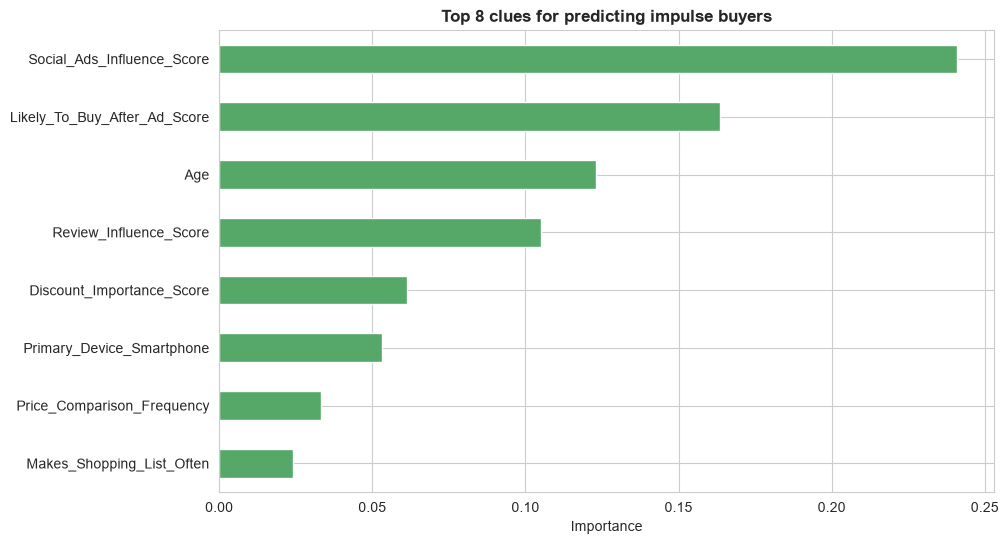

In [64]:
importance = pd.Series(rfc.feature_importances_, index=X.columns).sort_values().tail(8)
print(importance.sort_values(ascending=False).round(3))

importance.plot(kind="barh", color="#55A868")
plt.title("Top 8 clues for predicting impulse buyers", fontweight="bold")
plt.xlabel("Importance")
plt.show()

- The model relies most on **social-ad influence and on likehood to buy after an ad. Age** comes third, and review influence fourth.

- This matches the correlation chart: people who react to ads are the most likely impluse buyers. The other clues have smaller importance.

- Importance shows what the model used, not what truly causes impulse buying.